# Parking Occupancy: Where Is the Real Shortage?

A plaza owner in Bradenton, Florida is weighing a parking investment. Before spending, the owner needs to know whether drivers face a true capacity shortage or a distribution problem. Four weeks of readings across nine lots answer that question.

In [1]:
import sys
sys.path.insert(0, '..')
import matplotlib.pyplot as plt
from src import eda

df = eda.load('../data/parking_occupancy.csv')
print(f'{len(df):,} readings, {df.lot_code.nunique()} lots, {df.timestamp.min():%b %d} to {df.timestamp.max():%b %d, %Y}')
df.head()

4,138 readings, 9 lots, Nov 20 to Dec 17, 2022


,lot_code,lot_capacity,lot_occupancy,timestamp,day,occupancy_rate,date,hour,over_capacity
0,Lot01,863,174,2022-11-20 08:01:00,Sunday,20.16,2022-11-20,8,False
1,Lot01,863,179,2022-11-20 08:27:00,Sunday,20.74,2022-11-20,8,False
2,Lot01,863,189,2022-11-20 09:01:00,Sunday,21.90,2022-11-20,9,False
3,Lot01,863,197,2022-11-20 09:27:00,Sunday,22.83,2022-11-20,9,False
4,Lot01,863,226,2022-11-20 10:01:00,Sunday,26.19,2022-11-20,10,False


## 1. Lot by lot

In [2]:
eda.lot_summary(df)

,capacity,readings,mean_rate,median_rate,p90_rate,share_of_readings_over_90pct
lot_code,,,,,,
Lot02,387,466,85.4,97.7,100.0,62.2
Lot01,863,448,78.8,86.0,99.0,42.6
Lot09,720,446,74.0,80.5,96.2,29.4
Lot07,687,466,71.7,75.4,93.3,16.1
Lot06,220,448,66.6,79.3,96.8,30.8
Lot05,470,466,66.1,76.3,95.0,22.3
Lot03,1194,466,54.0,59.3,97.1,13.1
Lot08,1200,466,52.3,58.0,71.2,0.0
Lot04,849,466,31.7,32.8,48.6,0.0


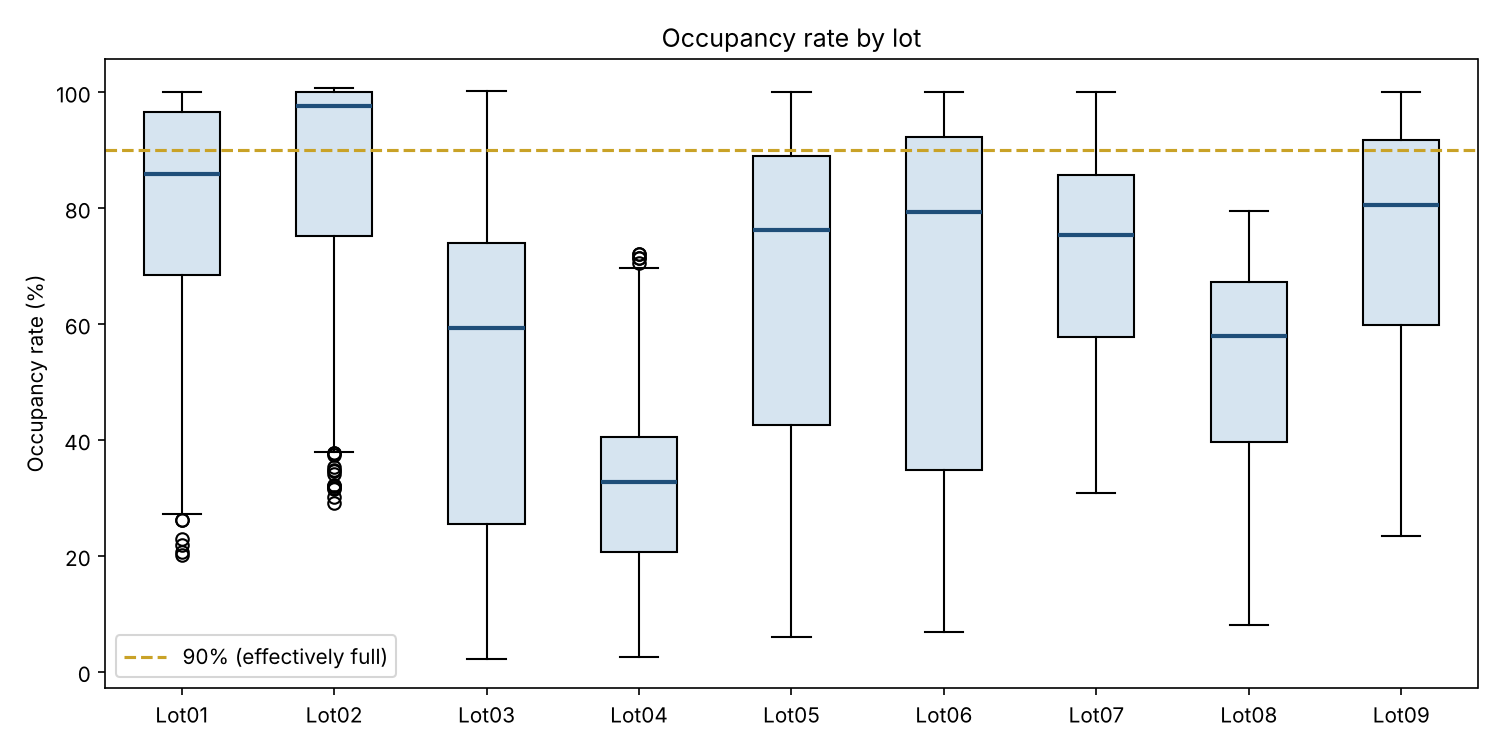

In [3]:
from pathlib import Path
from IPython.display import Image
fig_dir = Path('figures'); fig_dir.mkdir(exist_ok=True)
Image(eda.plot_lot_boxplot(df, fig_dir))

## 2. Day of week
Tuesday through Thursday carry the highest medians. Sunday runs lowest.

In [4]:
eda.day_summary(df)

,mean,median,std
day,,,
Monday,66.4,71.8,25.9
Tuesday,69.6,73.9,26.1
Wednesday,70.3,75.1,26.1
Thursday,70.4,75.8,25.9
Friday,67.5,71.8,22.9
Saturday,53.3,52.6,28.3
Sunday,45.8,40.4,29.9


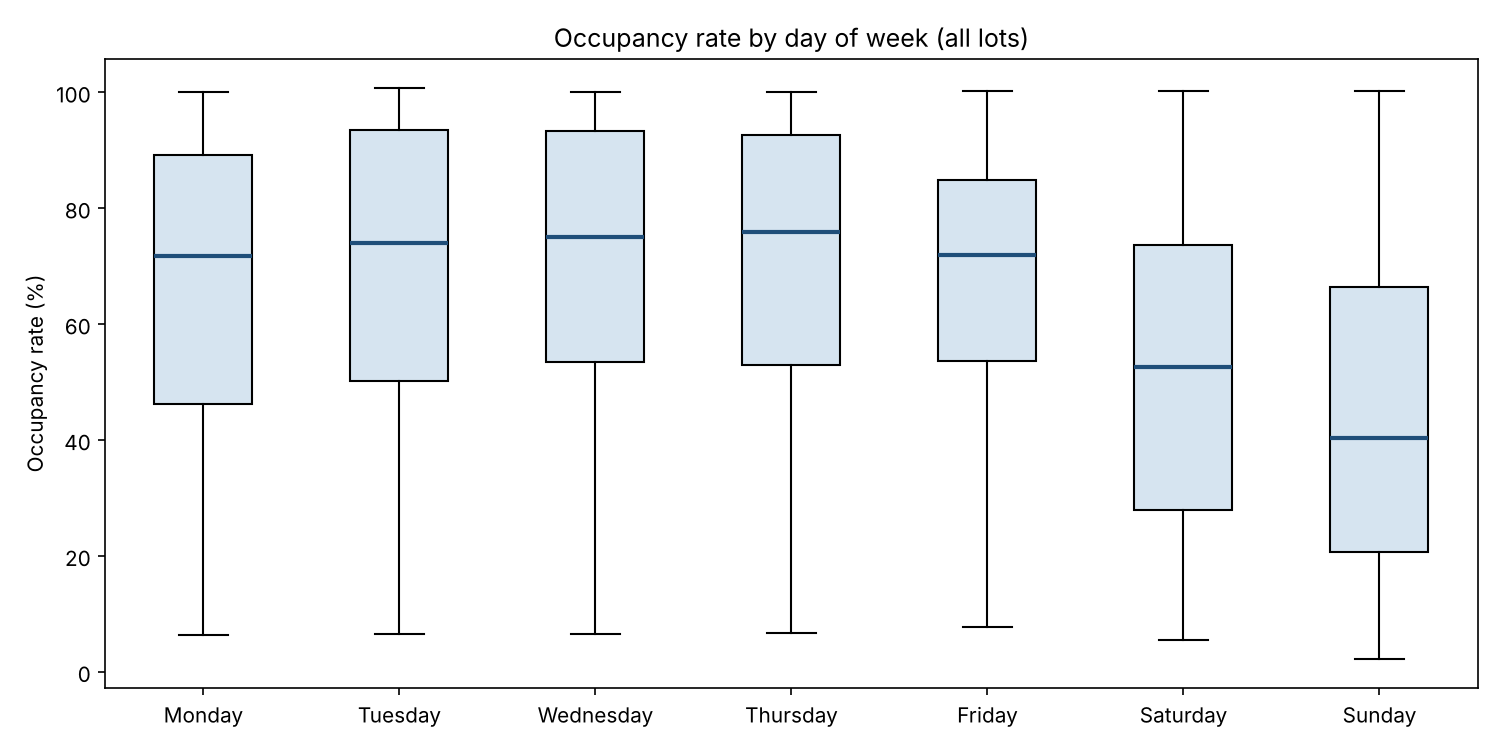

In [5]:
Image(eda.plot_day_boxplot(df, fig_dir))

## 3. Time of day
Every lot peaks in the same 11:00 to 14:00 band.

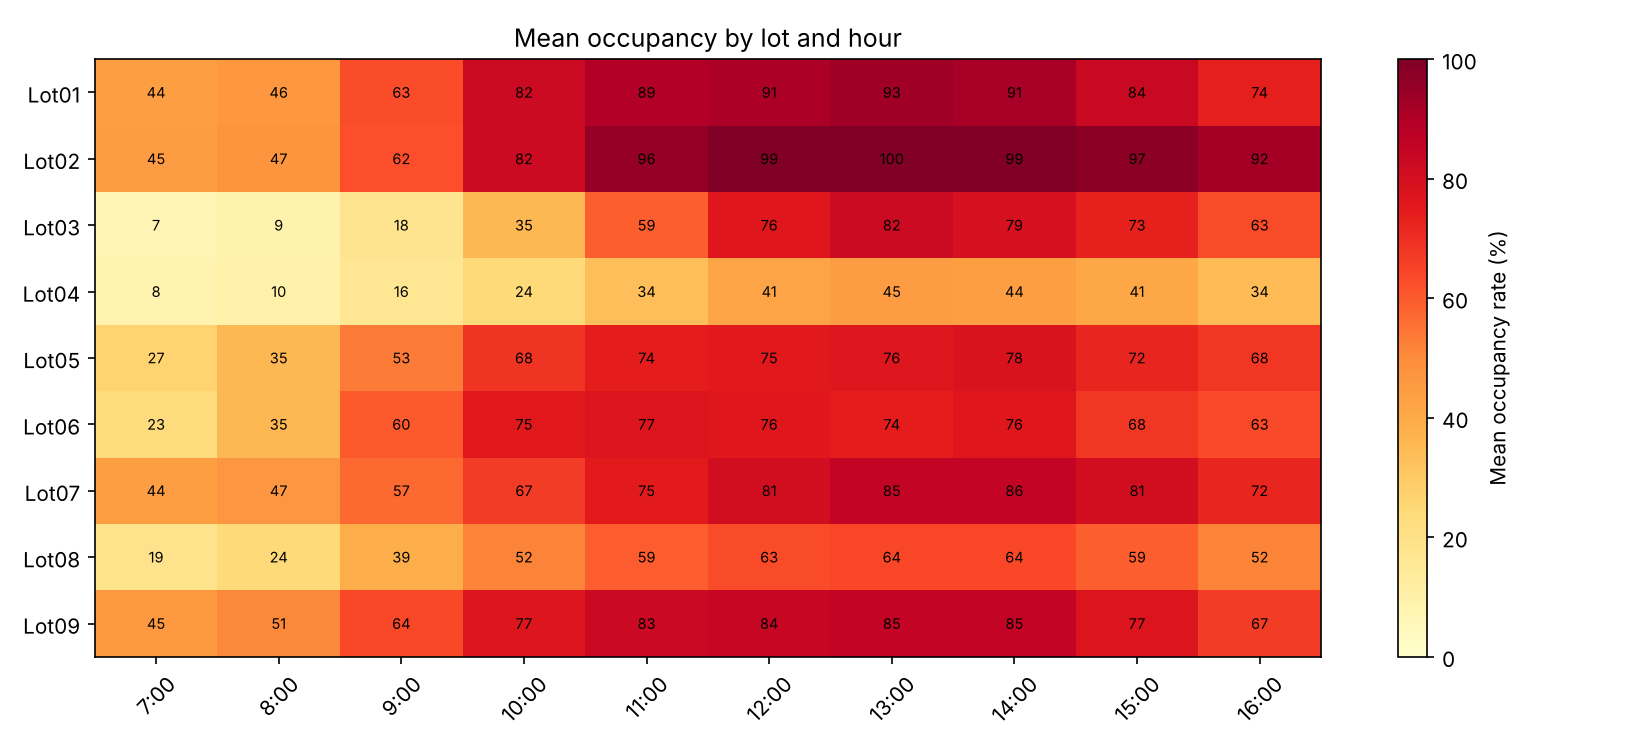

In [6]:
Image(eda.plot_heatmap(df, fig_dir))

## 4. The two extremes: Lot02 and Lot04

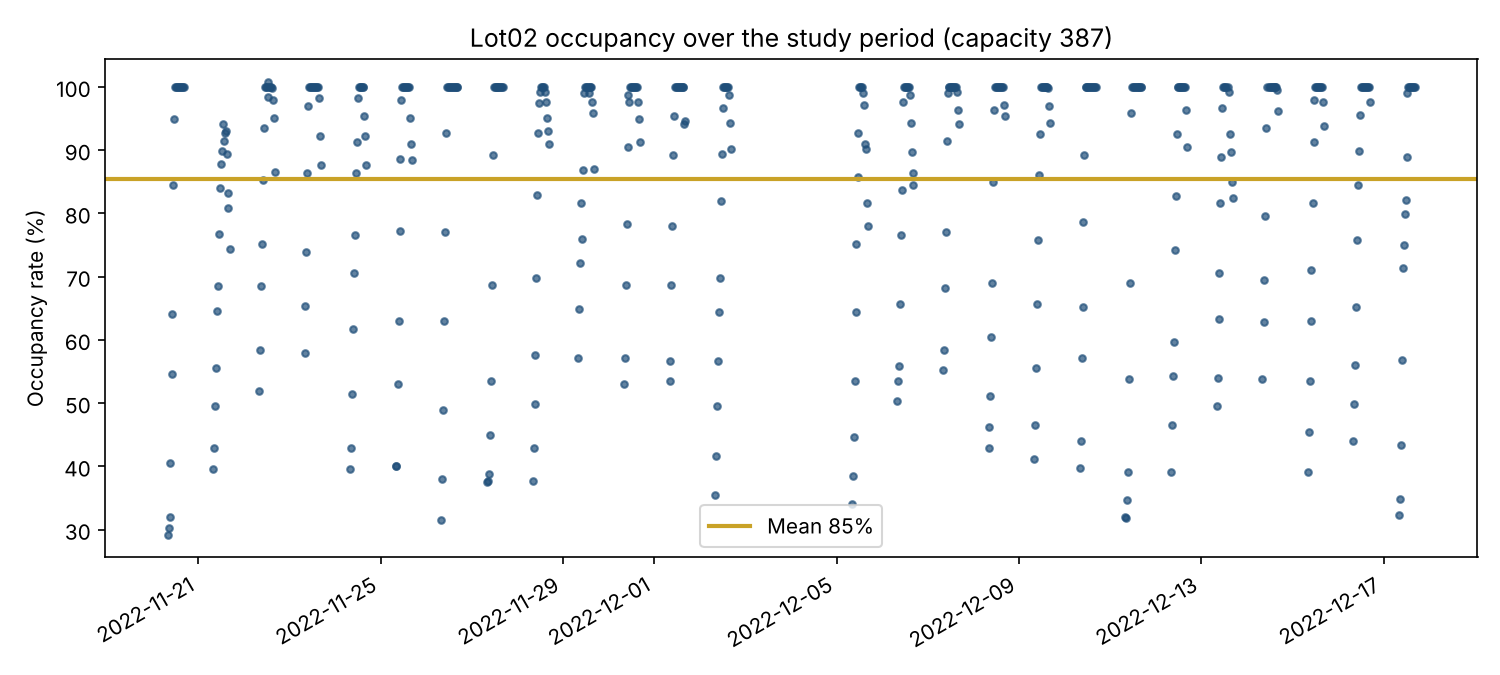

In [7]:
Image(eda.plot_lot_scatter(df, 'Lot02', fig_dir))

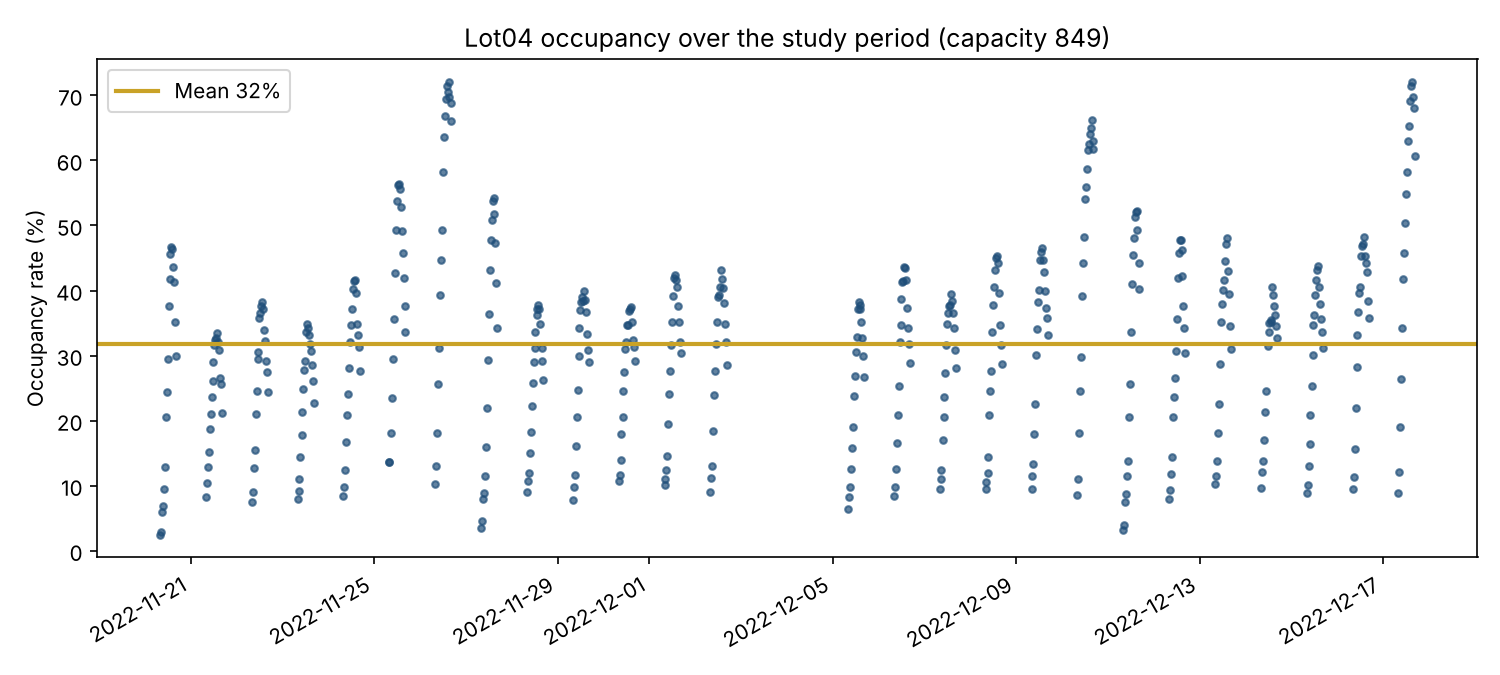

In [8]:
Image(eda.plot_lot_scatter(df, 'Lot04', fig_dir))

## 5. Open spaces at the weekday midday peak

In [9]:
peak = df[df.hour.between(11, 14) & ~df.day.isin(['Saturday', 'Sunday'])]
(peak.lot_capacity - peak.lot_occupancy).groupby(peak.lot_code).mean().round(0).sort_values()

lot_code
Lot02      6.0
Lot06     22.0
Lot01     33.0
Lot05     50.0
Lot09     54.0
Lot07     97.0
Lot03    371.0
Lot08    379.0
Lot04    526.0
dtype: float64

## Findings

1. **This is a distribution problem, not a capacity problem.** At the weekday midday peak Lot02 averages about 6 open spaces while Lot04 averages about 526 and Lots 03 and 08 each hold about 370.
2. **Lot02 is effectively full most of the day.** 62 percent of its readings sit at or above 90 percent, and it logs readings over capacity.
3. **Demand follows the work week.** Tuesday to Thursday medians sit near 75 percent. Sunday drops to about 40 percent.
4. **One shared peak.** All nine lots crest between 11:00 and 14:00.

## Recommendation
Pilot real time availability signs and app guidance that steer drivers from Lots 01 and 02 to Lots 03, 04, and 08 before funding new capacity. Measure success by the drop in Lot02 readings above 90 percent.